# 02 tokenizer

Step 2 of the guide: every transaction becomes a fixed-order row of tokens, the rows of a card are concatenated in time order and cut into 512-token windows. Each stage below shows what it produced.

```
<TX>  DT_k  HOUR_k  CAT_x  MER_x  AMT_k  DIST_k        7 tokens per transaction
       |      |       |      |      |      |
       |      |       |      |      |      home-to-merchant km, 8 log bins          (switch use_dist)
       |      |       |      |      amount, 20 bins, log or linear, edges fit on train
       |      |       |      merchant if in the train top-500, else MER_OTHER
       |      |       category, one token each
       |      hour of day, 6 periods of 4 h
       minutes since this card's previous transaction, 12 fixed log-spaced bins, DT_NA on a card's first row   (switch use_dt)
```


In [1]:
import os, sys, glob, shutil
from google.colab import drive, userdata
drive.mount("/content/drive")
ROOT = "/content/drive/MyDrive/Colab Notebooks/tfm"
tok = userdata.get("GH_TOKEN")
if not os.path.exists("/content/transaction-fm"):
    !git clone -q https://{tok}@github.com/lb603487485/transaction-fm.git /content/transaction-fm
else:
    !cd /content/transaction-fm && git pull -q
%pip install -q datasets xgboost
%cd /content/transaction-fm
sys.path.insert(0, "/content/transaction-fm/src")
os.makedirs(f"{ROOT}/notebooks", exist_ok=True)
for f in glob.glob("notebooks/*.ipynb"):          # new notebooks from the repo appear in Drive
    dst = f"{ROOT}/notebooks/{os.path.basename(f)}"
    if not os.path.exists(dst):
        shutil.copy(f, dst); print("new notebook in Drive:", os.path.basename(f))
import tfm
print("tfm ok")

Mounted at /content/drive
/content/transaction-fm
tfm ok


## What is fit, and on what

Learned from data: amount bin edges, distance bin edges, the category list, the merchant top-N. All of it inside `TransactionTokenizer.fit`, which starts with `assert_train_only` and raises if a val or test row is present (`tests/test_tokenizer.py::test_fit_refuses_non_train_rows`). Fixed by definition, nothing learned: the DT edges (1 min, 10 min, 30 min, 1 h, 3 h, 6 h, 12 h, 1 d, 2 d, 5 d, 30 d) and the 6 hour periods. Val and test rows are then encoded with the train vocabulary; whatever they contain that train never saw shows up as `<UNK>` or `MER_OTHER`, and Stage 2c counts how often.


## Stage 2a: fit on train rows, vocabulary

In [2]:
import json, numpy as np, pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
from tfm.data import train_only
from tfm.tokenizer import TransactionTokenizer, make_windows, DT_EDGES_MIN, HOUR_NAMES

df = pd.read_parquet(f"{ROOT}/data/processed/transactions.parquet")
tr = train_only(df)
print("rows:", len(df), " train rows used for fit:", len(tr))

tok = TransactionTokenizer(use_dt=True, use_dist=True, amt_binning="log", n_amt_bins=20, n_dist_bins=8, top_merchants=500).fit(tr)
print("vocab size:", len(tok.vocab), " tokens per transaction:", tok.tokens_per_tx)
print("merchants in train:", tr["merchant"].nunique(), " kept as own token:", len(tok.merchants))
print("special tokens:", {t: tok.vocab[t] for t in ["<PAD>", "<BOS>", "<MASK>", "<UNK>", "<TX>"]},
      "  (<BOS> is used by step 3, <MASK> by the MLM ablation in step 6; neither appears in step 2 output)")
tok.vocab_summary().to_frame("tokens")


rows: 1852394  train rows used for fit: 1212704
vocab size: 567  tokens per transaction: 7
merchants in train: 693  kept as own token: 500
special tokens: {'<PAD>': 0, '<BOS>': 1, '<MASK>': 2, '<UNK>': 3, '<TX>': 4}   (<BOS> is used by step 3, <MASK> by the MLM ablation in step 6; neither appears in step 2 output)


,tokens
special,5
DT,13
HOUR,6
CAT,14
MER,501
AMT,20
DIST,8


## Stage 2b: the bin edges, in human units

In [3]:
def edge_table(edges, unit, lo_label="-inf"):
    lo = [lo_label] + [f"{e:,.2f}" for e in edges]
    hi = [f"{e:,.2f}" for e in edges] + ["inf"]
    return pd.DataFrame({"bin": range(len(edges) + 1), f"from ({unit})": lo, f"to ({unit})": hi})

dt = edge_table(np.array(DT_EDGES_MIN), "min", "0")
dt["token"] = [f"DT_{i:02d}" for i in range(len(DT_EDGES_MIN) + 1)]
print("DT: fixed edges (DT_NA for the first row of a card)"); display(dt)

amt = edge_table(tok.amt_edges, "USD", "0"); amt["token"] = [f"AMT_{i:02d}" for i in range(len(amt))]
amt["train rows"] = np.bincount(tok.amt_bin(tr["amt"].to_numpy()), minlength=len(amt))
print("AMT: edges fit on train, evenly spaced in log1p between the train 1st and 99th percentile"); display(amt)

dist = edge_table(tok.dist_edges, "km", "0"); dist["token"] = [f"DIST_{i:02d}" for i in range(len(dist))]
dist["train rows"] = np.bincount(tok.dist_bin(tr["dist_km"].to_numpy()), minlength=len(dist))
print("DIST: same construction"); dist


DT: fixed edges (DT_NA for the first row of a card)


,bin,from (min),to (min),token
0,0,0,1.00,DT_00
1,1,1.00,10.00,DT_01
2,2,10.00,30.00,DT_02
3,3,30.00,60.00,DT_03
4,4,60.00,180.00,DT_04
5,5,180.00,360.00,DT_05
6,6,360.00,720.00,DT_06
7,7,720.00,"1,440.00",DT_07
8,8,"1,440.00","2,880.00",DT_08
9,9,"2,880.00","7,200.00",DT_09


AMT: edges fit on train, evenly spaced in log1p between the train 1st and 99th percentile


,bin,from (USD),to (USD),token,train rows
0,0,0,1.26,AMT_00,11929
1,1,1.26,2.07,AMT_01,34025
2,2,2.07,3.16,AMT_02,41018
3,3,3.16,4.64,AMT_03,52639
4,4,4.64,6.65,AMT_04,67421
5,5,6.65,9.38,AMT_05,87657
6,6,9.38,13.08,AMT_06,46906
7,7,13.08,18.10,AMT_07,40913
8,8,18.10,24.91,AMT_08,50474
9,9,24.91,34.15,AMT_09,67268


DIST: same construction


,bin,from (km),to (km),token,train rows
0,0,0,11.07,DIST_00,12128
1,1,11.07,17.00,DIST_01,16433
2,2,17.00,25.86,DIST_02,37776
3,3,25.86,39.07,DIST_03,85089
4,4,39.07,58.78,DIST_04,190949
5,5,58.78,88.18,DIST_05,419105
6,6,88.18,132.05,DIST_06,439096
7,7,132.05,inf,DIST_07,12128


## Stage 2c: worked example, one card, six consecutive transactions

Left the raw columns, right the tokens they became. This is the same shape as the Wells Fargo worked-example slide. Then the flat token stream those six rows contribute to the card's sequence.


In [4]:
cid = int(df["card_id"].value_counts().index[len(df["card_id"].unique()) // 2])   # the median-activity card
one = df[df["card_id"] == cid].iloc[100:106].copy()
one["gap_min"] = one["ts"].diff().dt.total_seconds().div(60).round(1)
ids = tok.encode(df[df["card_id"] == cid].iloc[99:106])[1:]          # include the row before so the first DT is real
names = ["TX", "DT", "HOUR", "CAT", "MER", "AMT", "DIST"]
toks = pd.DataFrame([tok.decode(r) for r in ids], columns=names, index=one.index)
display(pd.concat([one[["ts", "gap_min", "category", "merchant", "amt", "dist_km", "is_fraud"]].round(2), toks], axis=1))
print("flat stream:", " ".join(tok.decode(ids)))
print("ids:        ", ids.ravel().tolist())


,ts,gap_min,category,merchant,amt,dist_km,is_fraud,TX,DT,HOUR,CAT,MER,AMT,DIST
203678,2019-03-06 17:42:21,NaN,kids_pets,"fraud_Yost, Schamberger and Windler",38.59,108.79,0,<TX>,DT_06,HOUR_EVENING,CAT_kids_pets,"MER_fraud_Yost, Schamberger and Windler",AMT_10,DIST_06
203679,2019-03-08 00:07:17,1824.9,grocery_pos,fraud_Kiehn Inc,80.09,108.31,0,<TX>,DT_08,HOUR_LATE_NIGHT,CAT_grocery_pos,MER_fraud_Kiehn Inc,AMT_12,DIST_06
203680,2019-03-08 10:57:21,650.1,grocery_pos,fraud_Auer-Mosciski,65.80,118.58,0,<TX>,DT_06,HOUR_MORNING,CAT_grocery_pos,MER_fraud_Auer-Mosciski,AMT_12,DIST_06
203681,2019-03-08 15:45:52,288.5,shopping_net,"fraud_Altenwerth, Cartwright and Koss",5.75,53.20,0,<TX>,DT_05,HOUR_AFTERNOON,CAT_shopping_net,"MER_fraud_Altenwerth, Cartwright and Koss",AMT_04,DIST_04
203682,2019-03-09 12:34:59,1249.1,home,fraud_Berge-Ullrich,22.22,80.11,0,<TX>,DT_07,HOUR_AFTERNOON,CAT_home,MER_fraud_Berge-Ullrich,AMT_08,DIST_05
203683,2019-03-09 14:07:14,92.2,shopping_net,fraud_Goyette Inc,2.97,93.90,0,<TX>,DT_04,HOUR_AFTERNOON,CAT_shopping_net,MER_fraud_Goyette Inc,AMT_02,DIST_06


flat stream: <TX> DT_06 HOUR_EVENING CAT_kids_pets MER_fraud_Yost, Schamberger and Windler AMT_10 DIST_06 <TX> DT_08 HOUR_LATE_NIGHT CAT_grocery_pos MER_fraud_Kiehn Inc AMT_12 DIST_06 <TX> DT_06 HOUR_MORNING CAT_grocery_pos MER_fraud_Auer-Mosciski AMT_12 DIST_06 <TX> DT_05 HOUR_AFTERNOON CAT_shopping_net MER_fraud_Altenwerth, Cartwright and Koss AMT_04 DIST_04 <TX> DT_07 HOUR_AFTERNOON CAT_home MER_fraud_Berge-Ullrich AMT_08 DIST_05 <TX> DT_04 HOUR_AFTERNOON CAT_shopping_net MER_fraud_Goyette Inc AMT_02 DIST_06
ids:         [4, 12, 22, 31, 529, 549, 565, 4, 14, 18, 28, 260, 551, 565, 4, 12, 20, 28, 48, 551, 565, 4, 11, 21, 35, 43, 543, 563, 4, 13, 21, 30, 78, 547, 564, 4, 10, 21, 35, 194, 541, 565]


Guide item 5, "sample a few sequences and check by hand": two random rows from val and two from test, raw columns next to their decoded tokens. Then the same check done by machine on 5,000 random rows: the decoded AMT bin must contain `amt`, the DT bin must contain the gap, CAT must equal `category`, MER must be the merchant or `MER_OTHER`.


In [5]:
ids_all = tok.encode(df)                      # every row, all splits, with the train-fit tokenizer
rng = np.random.default_rng(0)
pick = np.concatenate([rng.choice(np.flatnonzero(df["split"].to_numpy() == s), 2, replace=False) for s in ("val", "test")])
sample = df.iloc[pick].copy()
sample["gap_min"] = df.groupby("card_id")["ts"].diff().dt.total_seconds().div(60).iloc[pick].round(1).values
sample_toks = pd.DataFrame([tok.decode(r) for r in ids_all[pick]], columns=names, index=sample.index)
display(pd.concat([sample[["split", "card_id", "ts", "gap_min", "category", "merchant", "amt", "dist_km"]].round(2), sample_toks], axis=1))

check = rng.choice(len(df), min(5000, len(df)), replace=False)
gap_all = df.groupby("card_id")["ts"].diff().dt.total_seconds().div(60).to_numpy()
amt_lo = np.r_[-np.inf, tok.amt_edges]; amt_hi = np.r_[tok.amt_edges, np.inf]
dt_lo = np.r_[-np.inf, DT_EDGES_MIN]; dt_hi = np.r_[DT_EDGES_MIN, np.inf]
bad = 0
for k in check:
    t = tok.decode(ids_all[k]); r = df.iloc[k]
    a = int(t[5][4:]); ok_amt = amt_lo[a] <= r["amt"] < amt_hi[a]
    ok_dt = t[1] == "DT_NA" if np.isnan(gap_all[k]) else (dt_lo[int(t[1][3:])] <= gap_all[k] < dt_hi[int(t[1][3:])])
    ok_cat = t[3] == f"CAT_{r['category']}"
    ok_mer = t[4] in (f"MER_{r['merchant']}", "MER_OTHER")
    ok_hour = t[2] == f"HOUR_{HOUR_NAMES[r['ts'].hour // 4]}"
    bad += not (ok_amt and ok_dt and ok_cat and ok_mer and ok_hour and t[0] == "<TX>")
print(f"machine check on {len(check)} random rows: {len(check) - bad} consistent, {bad} inconsistent")
assert bad == 0


,split,card_id,ts,gap_min,category,merchant,amt,dist_km,TX,DT,HOUR,CAT,MER,AMT,DIST
1575714,val,843,2020-05-27 07:24:33,45.9,misc_pos,"fraud_Wiza, Schaden and Stark",246.29,58.81,<TX>,DT_03,HOUR_EARLY_MORNING,CAT_misc_pos,"MER_fraud_Wiza, Schaden and Stark",AMT_16,DIST_05
1182837,val,636,2020-06-07 18:11:26,48.5,shopping_pos,"fraud_Willms, Kris and Bergnaum",7.84,68.35,<TX>,DT_03,HOUR_EVENING,CAT_shopping_pos,"MER_fraud_Willms, Kris and Bergnaum",AMT_05,DIST_05
572446,test,309,2020-07-29 18:17:40,466.2,health_fitness,"fraud_Hyatt, Russel and Gleichner",71.32,69.49,<TX>,DT_06,HOUR_EVENING,CAT_health_fitness,"MER_fraud_Hyatt, Russel and Gleichner",AMT_12,DIST_05
502063,test,273,2020-09-04 02:41:39,760.6,grocery_net,fraud_Cummings Group,41.33,92.66,<TX>,DT_07,HOUR_LATE_NIGHT,CAT_grocery_net,MER_OTHER,AMT_10,DIST_06


machine check on 5000 random rows: 5000 consistent, 0 inconsistent


## Stage 2d: coverage per split

How much of each split falls into the fallback tokens. `MER_OTHER` is by design (merchants outside the train top-500); `<UNK>` means a category never seen in train; `AMT_00` / `AMT_19` and `DIST_00` / `DIST_07` hold everything beyond the train 1st / 99th percentile, so about 1 percent each on train and more on a split whose distribution moved.


In [6]:
v = tok.vocab
rows = []
for s in ("train", "val", "test"):
    m = (df["split"] == s).to_numpy(); x = ids_all[m]
    rows.append({"split": s, "rows": int(m.sum()),
                 "MER_OTHER": (x[:, 4] == v["MER_OTHER"]).mean(),
                 "CAT_<UNK>": (x[:, 3] == v["<UNK>"]).mean(),
                 "AMT first bin": (x[:, 5] == v["AMT_00"]).mean(), "AMT last bin": (x[:, 5] == v["AMT_19"]).mean(),
                 "DIST first bin": (x[:, 6] == v["DIST_00"]).mean(), "DIST last bin": (x[:, 6] == v["DIST_07"]).mean(),
                 "DT_NA": (x[:, 1] == v["DT_NA"]).mean()})
coverage = pd.DataFrame(rows).set_index("split")
coverage.style.format({c: "{:.2%}" for c in coverage.columns if c != "rows"})


,rows,MER_OTHER,CAT_,AMT first bin,AMT last bin,DIST first bin,DIST last bin,DT_NA
split,,,,,,,,
train,1212704,16.85%,0.00%,0.98%,1.00%,1.00%,1.00%,0.08%
val,83971,17.02%,0.00%,0.98%,1.01%,0.93%,1.02%,0.00%
test,555719,17.04%,0.00%,0.99%,0.90%,0.98%,0.98%,0.00%


## Stage 2e: the two switches, and why bins at all

The guide asks for two switches that step 6 will flip for ablations. Both are constructor arguments of `TransactionTokenizer`:

```
amt_binning="log" | "linear"     20 bins evenly spaced in log dollars, or in raw dollars
use_dt=True | False              with or without the time-gap token (7 or 6 tokens per transaction)
```

Why bins instead of the exact number: the Wealthsimple talk calls this the "custom vs text" trade-off. Binning throws away precision inside a bin (47 USD and 51 USD can become the same token), in exchange every field becomes a token and the standard GPT-2 architecture, loss and Hugging Face Trainer work unchanged, no custom numeric heads. The report has to state this trade-off; the cell below gives the number to state it with (how wide one AMT bin is), and shows what the linear alternative does to the same rows.


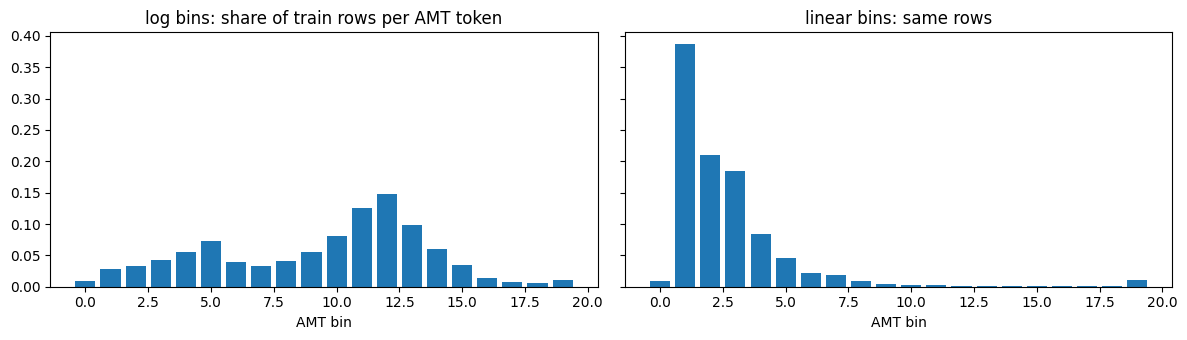

precision lost to binning: each of the 18 interior log bins spans a x1.36 range in dollars (edges 1.26 to 545.68); a linear bin is 30.25 USD wide everywhere
largest single bin, log: 14.8%  linear: 38.6%
empty or near-empty bins (<0.5% of rows), log: 0  linear: 10

switch use_dt=False: tokens per transaction 6  vocab 554
same row with DT:    <TX> DT_03 HOUR_EARLY_MORNING CAT_misc_pos MER_fraud_Wiza, Schaden and Stark AMT_16 DIST_05
same row without DT: <TX> HOUR_EARLY_MORNING CAT_misc_pos MER_fraud_Wiza, Schaden and Stark AMT_16 DIST_05


In [7]:
import matplotlib.pyplot as plt
lin = TransactionTokenizer(amt_binning="linear").fit(tr)
occ_log = np.bincount(tok.amt_bin(tr["amt"].to_numpy()), minlength=20) / len(tr)
occ_lin = np.bincount(lin.amt_bin(tr["amt"].to_numpy()), minlength=20) / len(tr)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
ax[0].bar(range(20), occ_log); ax[0].set_title("log bins: share of train rows per AMT token")
ax[1].bar(range(20), occ_lin); ax[1].set_title("linear bins: same rows")
for a in ax: a.set_xlabel("AMT bin")
plt.tight_layout(); plt.savefig(f"{ROOT}/results/02_amt_bins_log_vs_linear.png", dpi=120); plt.show()
ratio = (1 + tok.amt_edges[-1]) / (1 + tok.amt_edges[0])
print(f"precision lost to binning: each of the 18 interior log bins spans a x{ratio ** (1 / 18):.2f} range in dollars "
      f"(edges {tok.amt_edges[0]:.2f} to {tok.amt_edges[-1]:.2f}); a linear bin is {np.diff(lin.amt_edges)[0]:.2f} USD wide everywhere")
print("largest single bin, log:", f"{occ_log.max():.1%}", " linear:", f"{occ_lin.max():.1%}")
print("empty or near-empty bins (<0.5% of rows), log:", int((occ_log < 0.005).sum()), " linear:", int((occ_lin < 0.005).sum()))

no_dt = TransactionTokenizer(use_dt=False).fit(tr)
print("\nswitch use_dt=False: tokens per transaction", no_dt.tokens_per_tx, " vocab", len(no_dt.vocab))
print("same row with DT:   ", " ".join(tok.decode(ids_all[pick[0]])))
print("same row without DT:", " ".join(no_dt.decode(no_dt.encode(df.iloc[[pick[0]]])[0])))


## Stage 2f: windows

Each card's token rows of one split are concatenated in time order and cut into 512-token windows with stride 256 (half overlap). Windows never cross a card and never mix splits: train windows hold train rows only, val windows val rows only. A card with fewer than 512 tokens in a split gives one right-padded window.


In [ ]:
card = df["card_id"].to_numpy(); split = df["split"].to_numpy()
windows, metas = {}, {}
rows = []
for s in ("train", "val", "test"):
    w, m = make_windows(ids_all, card, split, s, seq_len=512, stride=256, pad_id=v["<PAD>"])
    windows[s], metas[s] = w, m
    rows.append({"split": s, "windows": len(w), "padded windows": int((m["n_real"] < 512).sum()),
                 "cards": m["card_id"].nunique(), "tokens (real)": int(m["n_real"].sum()),
                 "transactions per full window": 512 // tok.tokens_per_tx})
win = pd.DataFrame(rows).set_index("split"); display(win)
print("train tokens available for pretraining (rows x tokens_per_tx):", int((split == "train").sum()) * tok.tokens_per_tx)
print("first train window, decoded, first 21 tokens:", " ".join(tok.decode(windows["train"][0][:21])))


## Stage 2g: save

`tokenizer.json` (vocab, edges, config: this file travels with every checkpoint), `tokens_<split>.npy` and `windows_<split>_meta.parquet` under `data/processed/`, and `results/02_tokenizer.json` with the numbers above.


In [ ]:
import os
out = f"{ROOT}/data/processed"
tok.save(f"{out}/tokenizer.json")
for s in windows:
    np.save(f"{out}/tokens_{s}.npy", windows[s]); metas[s].to_parquet(f"{out}/windows_{s}_meta.parquet", index=False)
back = TransactionTokenizer.load(f"{out}/tokenizer.json")
print("reload gives identical encoding:", np.array_equal(back.encode(df.head(5000)), ids_all[:5000]))
res = {"vocab_size": len(tok.vocab), "tokens_per_tx": tok.tokens_per_tx, "config": tok.config,
       "vocab_composition": tok.vocab_summary().to_dict(), "coverage": coverage.to_dict(orient="index"),
       "windows": win.to_dict(orient="index"), "amt_edges_usd": tok.amt_edges.tolist(), "dist_edges_km": tok.dist_edges.tolist(),
       "amt_largest_bin_share": {"log": float(occ_log.max()), "linear": float(occ_lin.max())}}
json.dump(res, open(f"{ROOT}/results/02_tokenizer.json", "w"), indent=2)
print(sorted(os.listdir(out)))
j = json.load(open(f"{out}/tokenizer.json"))
print("\ntokenizer.json keys:", list(j))
print("config:", j["config"])
print("vocab[:8]:", j["vocab"][:8], "... vocab[-3:]:", j["vocab"][-3:])
print("amt_edges_usd[:5]:", [round(e, 2) for e in j["amt_edges"][:5]], " dist_edges_km:", [round(e, 1) for e in j["dist_edges"]])


## What to read off the numbers

- `vocab size` should land near 570 with top-500 merchants; the guide's 600 to 900 assumed more merchants than Sparkov's 693.
- `MER_OTHER` share on train tells you how much merchant information the top-500 cut throws away; if it is above 30 percent, raise `top_merchants` in step 6.
- Coverage on test versus train is the first drift signal: a test share in `AMT first/last bin` much above 1 percent means amounts moved; step 6's PSI per field makes this formal.
- `train tokens available` is the number step 3 sizes epochs against (the guide expected about 8M).


## Push results and this notebook back to GitHub

In [ ]:
import shutil, glob, os, json
os.makedirs("results/metrics", exist_ok=True); os.makedirs("results/figures", exist_ok=True)
for f in glob.glob(f"{ROOT}/results/*.json"):
    shutil.copy(f, "results/metrics/")
for f in glob.glob(f"{ROOT}/results/*.png"):
    shutil.copy(f, "results/figures/")
def same_code(a, b):   # a Drive notebook may be copied back only if its code cells equal the repo version
    cells = lambda p: ["".join(c["source"]) for c in json.load(open(p))["cells"] if c["cell_type"] == "code"]
    return cells(a) == cells(b)
for f in glob.glob(f"{ROOT}/notebooks/*.ipynb"):   # outputs are kept so GitHub shows them
    repo = f"notebooks/{os.path.basename(f)}"
    if not os.path.exists(repo) or same_code(f, repo):
        shutil.copy(f, repo)
    else:
        print("STALE, not copied:", os.path.basename(f), "-> delete it from Drive and rerun the setup cell")
!git config user.email "linboyy@hotmail.com" && git config user.name "Bo Lin"
!git add results notebooks && git commit -q -m "results and notebooks from Colab" && git push -q
!git log --oneline | head -1

In [ ]:
drive.flush_and_unmount()